(19968, 81)

,date_semaine,code_dept,As in PM10,BaP in PM10,Cd in PM10,Ni in PM10,Pb in PM10,NO2,O3,PM10,...,pct_ouvriers,pct_retraites,pct_sans_activite,pct_agriculteurs,densite_generalistes,densite_pediatres,densite_pneumologues,densite_allergologues,densite_kines,sos_present
0,2021-S01,01,0.326250,0.610000,0.0500,0.4225,0.002025,16.272727,20.909091,19.363636,...,14.2,26.0,12.9,0.6,53.439748,6.878368,1.016517,0.290433,77.400505,False
1,2021-S02,01,0.491563,1.065833,0.1375,3.0825,0.005350,22.257143,27.214286,13.928571,...,14.2,26.0,12.9,0.6,53.439748,6.878368,1.016517,0.290433,77.400505,False
2,2021-S03,01,0.581875,0.396667,0.0800,5.8525,0.008425,14.635714,50.714286,8.214286,...,14.2,26.0,12.9,0.6,53.439748,6.878368,1.016517,0.290433,77.400505,False
3,2021-S04,01,0.399687,0.385833,0.0900,3.4125,0.006250,21.864286,34.071429,11.428571,...,14.2,26.0,12.9,0.6,53.439748,6.878368,1.016517,0.290433,77.400505,False
4,2021-S05,01,0.390000,0.360833,0.0850,1.2350,0.004900,21.028571,30.428571,15.714286,...,14.2,26.0,12.9,0.6,53.439748,6.878368,1.016517,0.290433,77.400505,False


DatetimeIndex(['2021-01-04', '2021-01-11', '2021-01-18', '2021-01-25',
               '2021-02-01', '2021-02-08', '2021-02-15', '2021-02-22',
               '2021-03-01', '2021-03-08',
               ...
               '2024-10-21', '2024-10-28', '2024-11-04', '2024-11-11',
               '2024-11-18', '2024-11-25', '2024-12-02', '2024-12-09',
               '2024-12-16', '2024-12-23'],
              dtype='datetime64[us]', name='date_semaine', length=208, freq='W-MON')


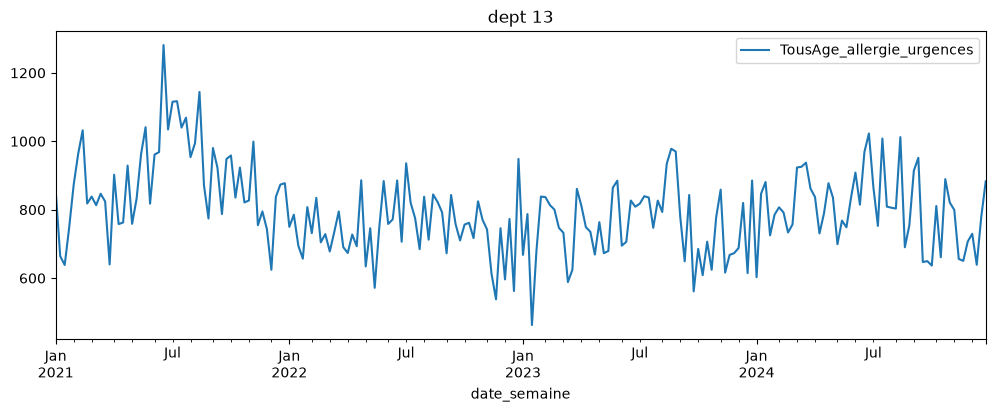

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

df=pd.read_csv('../data/final_metropole/Merge_final_2.csv',dtype={"code_dept": str})

display(df.shape)
display(df.head())

s13 = df.loc[df["code_dept"] == "13"]
dates = pd.to_datetime(s13["date_semaine"] + "-1", format="%G-S%V-%u")
s13 = s13.set_index(dates)[["TousAge_allergie_urgences"]]
s13 = s13.asfreq('W-MON')     
print(s13.index)

s13.plot(figsize=(12, 4));   
plt.title("dept 13");

In [2]:
annee = s13.index.year
train = s13[annee <= 2022]
val   = s13[annee == 2023]
test  = s13[annee == 2024]
print(len(train), len(val), len(test)) 


104 52 52


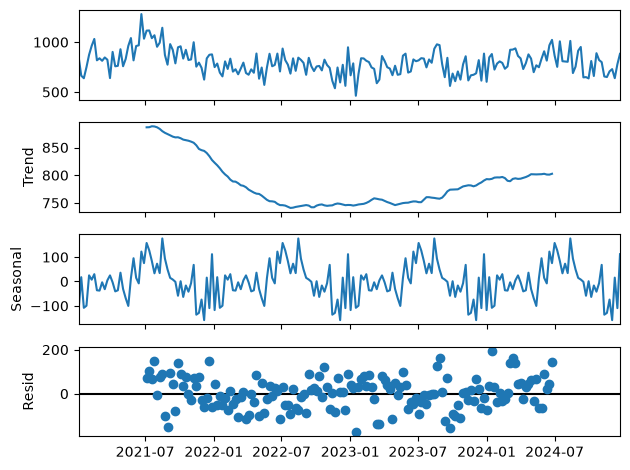

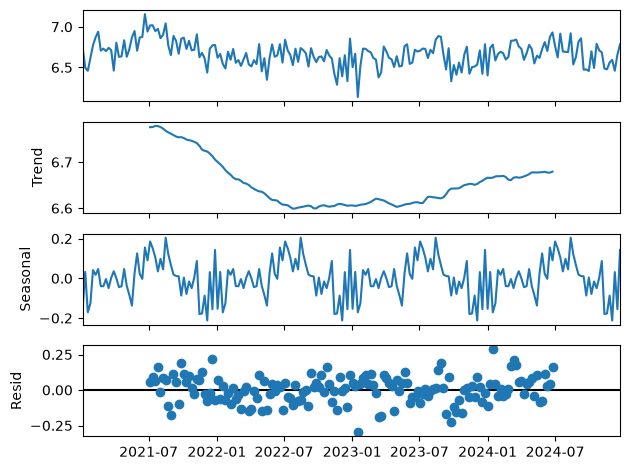

In [3]:
from statsmodels.tsa.seasonal import seasonal_decompose

res = seasonal_decompose(s13)
res.plot()
plt.show()

res = seasonal_decompose(np.log(s13))
res.plot()
plt.show()

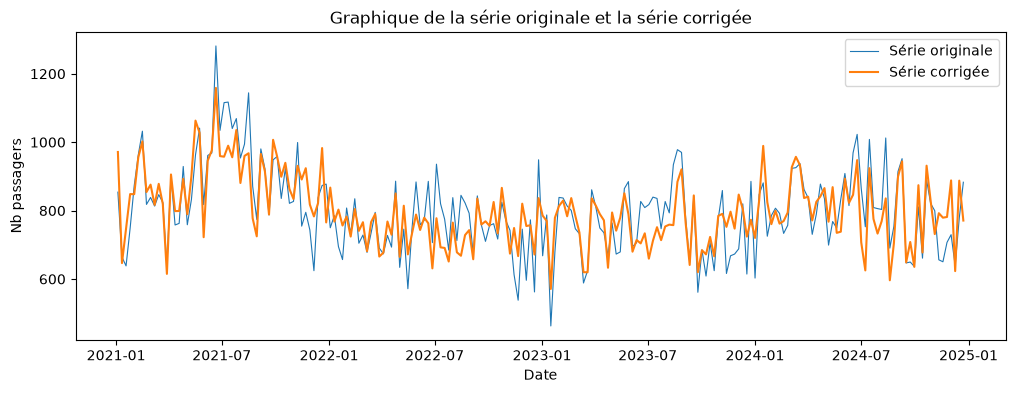

In [4]:
mult = seasonal_decompose(s13)

cvs = s13['TousAge_allergie_urgences'] - mult.seasonal

plt.figure(figsize=(12, 4))
plt.plot(s13, label='Série originale', linewidth=0.8)
plt.plot(cvs, label='Série corrigée')
plt.title('Graphique de la série originale et la série corrigée')
plt.xlabel('Date')
plt.ylabel('Nb passagers')
plt.legend()
plt.show();

/tmp/ipykernel_8326/643927733.py:14: FutureWarning: adfuller currently returns a plain tuple whose length depends on the store and autolag arguments. In release 0.16 or after July 2027, whichever is later, the default behavior will switch to always returning an ADFullerResult. Set result_object=True to switch now, or result_object=False to keep the current behavior and silence this warning.
  print(pd.Series({k: adfuller(v.dropna())[1] for k, v in transfos.items()}, name="p ADF").round(4))
/tmp/ipykernel_8326/643927733.py:14: FutureWarning: adfuller currently returns a plain tuple whose length depends on the store and autolag arguments. In release 0.16 or after July 2027, whichever is later, the default behavior will switch to always returning an ADFullerResult. Set result_object=True to switch now, or result_object=False to keep the current behavior and silence this warning.
  print(pd.Series({k: adfuller(v.dropna())[1] for k, v in transfos.items()}, name="p ADF").round(4))
/tmp/ipyke

brute               0.0625
diff(1)             0.0000
diff(52)            0.0000
diff(1)+diff(52)    0.0000
Name: p ADF, dtype: float64


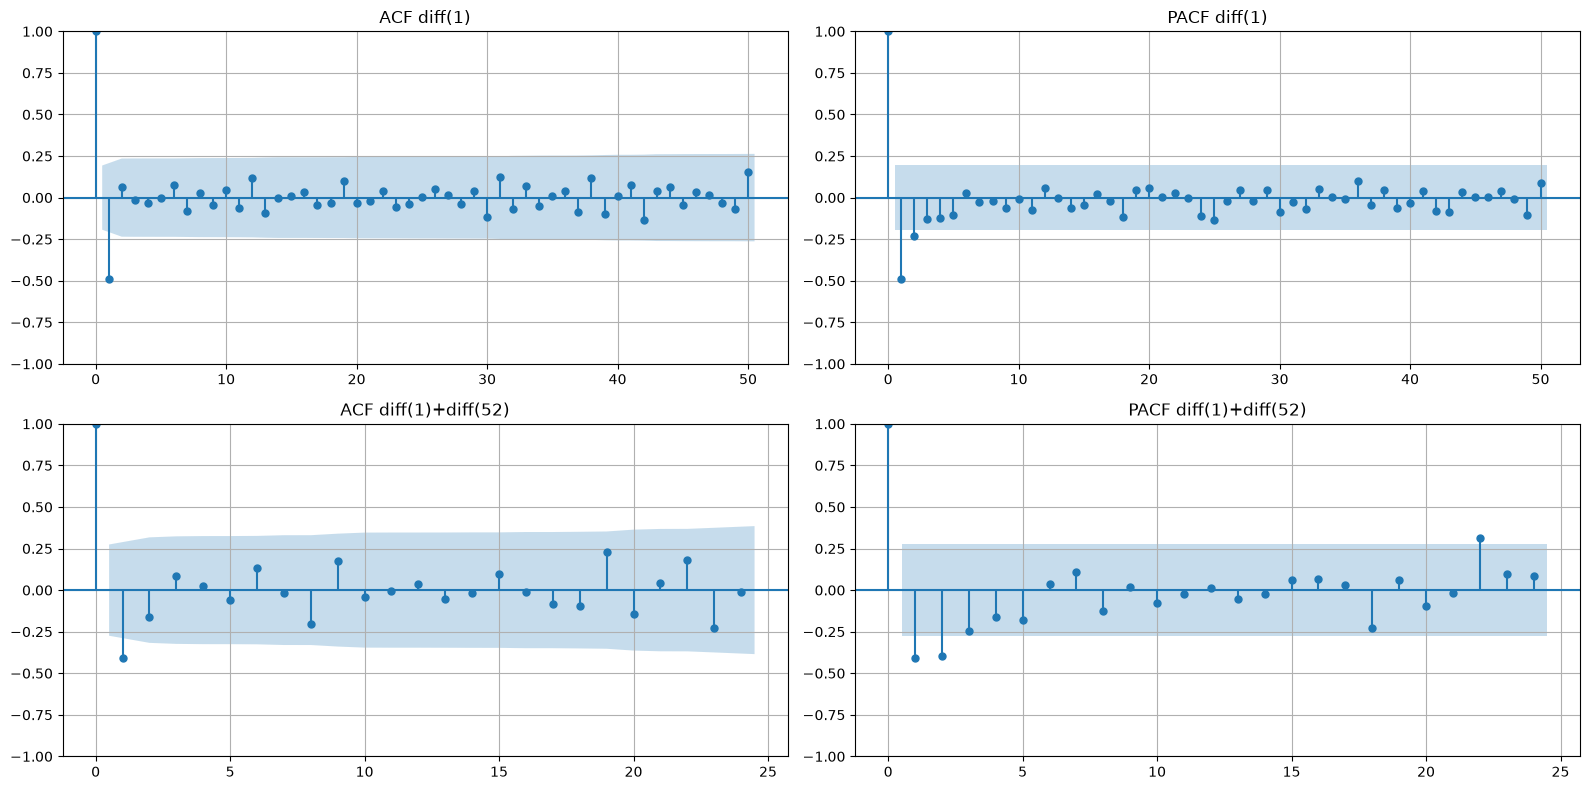

In [5]:
from statsmodels.tsa.stattools import adfuller
from statsmodels.graphics.tsaplots import plot_acf, plot_pacf

S = 52
y = s13["TousAge_allergie_urgences"].asfreq("W-MON")   
y_train = y[y.index.year <= 2022]

transfos = {
    "brute":           y_train,
    "diff(1)":         y_train.diff(1),
    "diff(52)":        y_train.diff(S),
    "diff(1)+diff(52)": y_train.diff(1).diff(S),
}
print(pd.Series({k: adfuller(v.dropna())[1] for k, v in transfos.items()}, name="p ADF").round(4))

fig, axes = plt.subplots(2, 2, figsize=(16, 8))
for row, (nom, serie) in enumerate([("diff(1)", y_train.diff(1)),
                                    ("diff(1)+diff(52)", y_train.diff(1).diff(S))]):
    s = serie.dropna()
    nlags = min(50, len(s) // 2 - 1)
    plot_acf(s, lags=nlags, ax=axes[row, 0], title=f"ACF {nom}")
    plot_pacf(s, lags=nlags, ax=axes[row, 1], title=f"PACF {nom}", method="ywm")
    for ax in axes[row]:
        ax.grid()
plt.tight_layout()
plt.show()

In [7]:
from statsmodels.tsa.statespace.sarimax import SARIMAX
from sklearn.metrics import r2_score, mean_absolute_error, root_mean_squared_error

y_val  = y[y.index.year == 2023]
y_test = y[y.index.year == 2024]

def one_step(order, sorder=(0, 0, 0, 0), fit_last_year=2022, eval_year=2023):
    """Estime le modèle sur les années y_train
    Renvoie le modèle ajusté et les prévisions à t+1 pour chaque semaine de y_eval"""
    trend = "c" if (order[1] == 0 and sorder[1] == 0) else "n"
    fit_m  = y.index.year <= fit_last_year
    hist_m = y.index.year <= eval_year
    res = SARIMAX(y[fit_m], order=order, seasonal_order=sorder,
                  trend=trend).fit(disp=False, maxiter=200)
    res_ext = res.apply(y[hist_m])                # mêmes paramètres, série prolongée
    start = y.index[y.index.year == eval_year][0]
    pred = res_ext.get_prediction(start=start)    # prévision à un pas (observations jusqu'à t-1)
    return res, pred

def scores(y_true, y_pred):
    m = y_true.notna() & y_pred.notna()
    return {"R2":   r2_score(y_true[m], y_pred[m]),
            "MAE":  mean_absolute_error(y_true[m], y_pred[m]),
            "RMSE": root_mean_squared_error(y_true[m], y_pred[m])}

In [12]:
import itertools, warnings
warnings.filterwarnings("ignore")   # SARIMAX émet beaucoup d'avertissements de convergence

results = []
for d, p, q in itertools.product([0, 1], [0, 1, 2], [0, 1]):
    order = (p, d, q)                                 # D = 0 
    res, pred = one_step(order)                       # ajustement 2021-2022, prévisions t+1 sur 2023
    m = scores(y_val, pred.predicted_mean)            # scores sur 2023
    results.append([order, d, res.bic, m["R2"], m["MAE"], m["RMSE"]])

grid = pd.DataFrame(results, columns=["order", "d", "BIC", "R2", "MAE", "RMSE"])
grid = grid.sort_values("RMSE").reset_index(drop=True)   # classement des modèles sur RMSE
display(grid.head(10).round(3))

,order,d,BIC,R2,MAE,RMSE
0,"(1, 0, 1)",0,1284.617,-0.015,87.289,107.032
1,"(0, 1, 1)",1,1266.534,-0.050,88.221,108.822
2,"(2, 1, 1)",1,1275.108,-0.060,88.235,109.344
3,"(2, 0, 1)",0,1291.400,-0.064,89.883,109.546
4,"(2, 0, 0)",0,1288.875,-0.065,89.363,109.628
5,"(1, 1, 1)",1,1270.646,-0.078,88.846,110.267
6,"(1, 0, 0)",0,1298.107,-0.141,87.740,113.437
7,"(0, 0, 1)",0,1310.600,-0.236,89.849,118.109
8,"(1, 1, 0)",1,1279.155,-0.237,93.549,118.126
9,"(2, 1, 0)",1,1276.537,-0.249,95.947,118.724


#### Deux observations :
#### Tous les R2 sont négatifs => très mauvaise prédictions
#### Plusieurs modèles présentent un meilleur BIC que (1, 0, 1)
####
#### Question : quel est le meilleur modèle par département ?

In [9]:
# Grille des order sur tous les départements : quel modèle est le meilleur où ?
import itertools, warnings
import pandas as pd
from statsmodels.tsa.statespace.sarimax import SARIMAX
from sklearn.metrics import r2_score, root_mean_squared_error
warnings.filterwarnings("ignore")                       # avertissements de convergence

CIBLE_G = "TousAge_allergie_urgences"
ORDRES  = [(p, d, q) for d, p, q in itertools.product([0, 1], [0, 1, 2], [0, 1])]   # 12 modèles

def serie_g(dept):
    """Série hebdomadaire de la cible pour un département (lundi de chaque semaine ISO)."""
    d = df.loc[df["code_dept"] == dept].copy()
    d.index = pd.to_datetime(d["date_semaine"] + "-1", format="%G-S%V-%u")
    return d[~d.index.duplicated()].sort_index().asfreq("W-MON")[CIBLE_G]

def one_step_g(y, o, fit_last_year=2022, eval_year=2023):
    """Ajustement jusqu'à fit_last_year, prévision t+1 sur eval_year, sans exogène."""
    trend = "c" if o[1] == 0 else "n"
    res = SARIMAX(y[y.index.year <= fit_last_year], order=o, trend=trend).fit(disp=False, maxiter=200)
    res_ext = res.apply(y[y.index.year <= eval_year])
    start = y.index[y.index.year == eval_year][0]
    return res, res_ext.get_prediction(start=start).predicted_mean

lignes = []
for dept in sorted(df["code_dept"].unique()):
    y_d = serie_g(dept)
    y_v = y_d[y_d.index.year == 2023]
    for o in ORDRES:
        try:
            res, pred = one_step_g(y_d, o)
            pred = pred.reindex(y_v.index)
            ok = y_v.notna() & pred.notna()
            lignes.append([dept, o, o[1], res.bic,
                           r2_score(y_v[ok], pred[ok]),
                           root_mean_squared_error(y_v[ok], pred[ok])])
        except Exception:
            pass                                        # modèle non estimable : ignoré
    print(dept, end=" ")                                # suivi de progression

G = pd.DataFrame(lignes, columns=["dept", "order", "d", "BIC", "R2", "RMSE"])

# Nombre de départements où chaque order est le meilleur
best_rmse = G.loc[G.groupby("dept")["RMSE"].idxmin()]                           # critère : RMSE 2023
best_bic0 = G[G["d"] == 0].loc[lambda t: t.groupby("dept")["BIC"].idxmin()]    # critère : BIC, à d=0
display(pd.concat([best_rmse["order"].value_counts().rename("meilleur RMSE"),
                   best_bic0["order"].value_counts().rename("meilleur BIC (d=0)")], axis=1)
        .fillna(0).astype(int))

01 02 03 04 05 06 07 08 09 10 11 12 13 14 15 16 17 18 19 21 22 23 24 25 26 27 28 29 2A 2B 30 31 32 33 34 35 36 37 38 39 40 41 42 43 44 45 46 47 48 49 50 51 52 53 54 55 56 57 58 59 60 61 62 63 64 65 66 67 68 69 70 71 72 73 74 75 76 77 78 79 80 81 82 83 84 85 86 87 88 89 90 91 92 93 94 95 

,meilleur RMSE,meilleur BIC (d=0)
order,,
"(1, 0, 1)",40,43
"(0, 1, 1)",18,0
"(2, 0, 1)",15,3
"(2, 1, 0)",5,0
"(0, 0, 0)",4,4
"(1, 0, 0)",3,26
"(2, 0, 0)",3,19
"(1, 1, 1)",2,0
"(1, 1, 0)",2,0


#### Le modèle (1, 0, 1) est le meilleur modèle dans ~ 50% départements
#### Combien "coute" l'utilisation de ce modèle dans TOUS les départements ?

In [26]:
# Diagnostic de l'order commun (1,0,1) : marge par rapport au meilleur, et qualité absolue
rmse_best = G.groupby("dept")["RMSE"].min()
g101 = G[G["order"] == (1, 0, 1)].set_index("dept")
surcout = 100 * (g101["RMSE"] / rmse_best - 1)            # % de RMSE perdu en imposant (1,0,1)

diag = pd.DataFrame({"surcout_%": surcout, "R2_101": g101["R2"]}).round(3)

print("Surcoût de (1,0,1) par rapport au meilleur modèle (%) :")
print(diag["surcout_%"].describe().round(2))
print(f"\n{(diag['surcout_%'] > 5).sum()} départements où (1,0,1) perd plus de 5 %")

# Départements où le surcoût dépasse 5 %, du plus pénalisé au moins pénalisé
print(", ".join(diag[diag["surcout_%"] > 5].sort_values("surcout_%", ascending=False).index))   # surcoût décroissant

Surcoût de (1,0,1) par rapport au meilleur modèle (%) :
count    96.00
mean      2.22
std       3.55
min       0.00
25%       0.00
50%       0.43
75%       3.30
max      20.34
Name: surcout_%, dtype: float64

18 départements où (1,0,1) perd plus de 5 %
58, 76, 18, 43, 64, 31, 71, 95, 51, 47, 17, 24, 81, 59, 32, 16, 40, 48
